<a href="https://colab.research.google.com/github/masagcabenedick-oss/fuel-inventory-variance-analysis/blob/main/Fuel_Inventory_Variance_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Pinakamababang closing stock: 9775
flag
OK       259
CHECK     11
Name: count, dtype: int64
          date tank   product  opening  received  issued  closing  \
6   2026-07-07   T1    Diesel    24186         0    4324    19060   
61  2026-08-31   T1    Diesel    34302         0    3955    29554   
135 2026-08-15   T2  Gasoline    28740         0    5017    22954   
124 2026-08-04   T2  Gasoline    37147         0    4070    32323   
77  2026-09-16   T1    Diesel    46391         0    2160    43587   

     expected_closing  variance   flag  
6               19862      -802  CHECK  
61              30347      -793  CHECK  
135             23723      -769  CHECK  
124             33077      -754  CHECK  
77              44231      -644  CHECK  


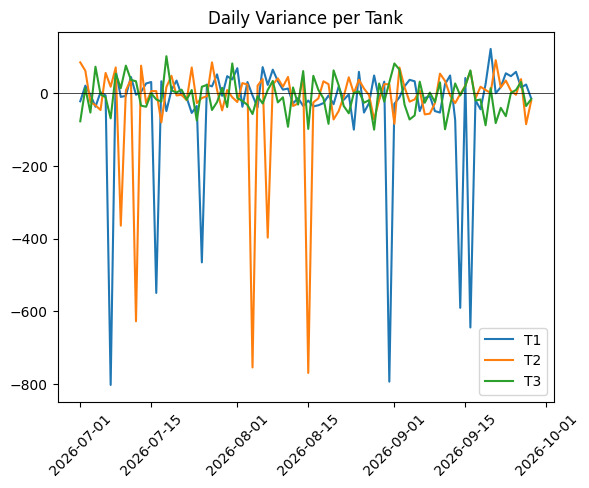

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

dates = pd.date_range("2026-07-01", periods=90)
rows = []
for tank, product in [("T1", "Diesel"), ("T2", "Gasoline"), ("T3", "Kerosene")]:
    stock = 50000
    for d in dates:
        # May delivery kapag mababa na ang stock (parang totoong depot)
        received = 40000 if stock < 15000 else 0
        issued = np.random.randint(2000, 6000)
        expected = stock + received - issued
        closing = expected + np.random.normal(0, 40)
        if np.random.rand() < 0.04:
            closing -= np.random.randint(300, 900)
        rows.append([d, tank, product, stock, received, issued, round(closing)])
        stock = round(closing)

df = pd.DataFrame(rows, columns=["date", "tank", "product", "opening", "received", "issued", "closing"])

df["expected_closing"] = df["opening"] + df["received"] - df["issued"]
df["variance"] = df["closing"] - df["expected_closing"]
df["flag"] = np.where(df["variance"].abs() > 200, "CHECK", "OK")

print("Pinakamababang closing stock:", df["closing"].min())
print(df["flag"].value_counts())
print(df.loc[df["variance"].abs().nlargest(5).index])

for tank, g in df.groupby("tank"):
    plt.plot(g["date"], g["variance"], label=tank)
plt.axhline(0, color="black", linewidth=0.5)
plt.title("Daily Variance per Tank")
plt.legend()
plt.xticks(rotation=45)
plt.show()

df.to_csv("fuel_inventory.csv", index=False)


In [2]:
import sqlite3

conn = sqlite3.connect(":memory:")
df["date"] = df["date"].astype(str)
df.to_sql("fuel", conn, index=False, if_exists="replace")

def q(sql):
    return pd.read_sql(sql, conn)

print("1. Total variance bawat tank")
print(q("""
SELECT tank, product,
       SUM(variance) AS total_variance,
       ROUND(AVG(variance), 1) AS avg_variance
FROM fuel
GROUP BY tank, product
"""))

print("2. Total variance bawat buwan")
print(q("""
SELECT SUBSTR(date, 1, 7) AS month, tank,
       SUM(variance) AS total_variance
FROM fuel
GROUP BY month, tank
ORDER BY month, tank
"""))

print("3. Top 5 pinakamalaking loss")
print(q("""
SELECT date, tank, product, variance
FROM fuel
ORDER BY variance ASC
LIMIT 5
"""))

print("4. CHECK days bawat tank")
print(q("""
SELECT tank, COUNT(*) AS check_days
FROM fuel
WHERE flag = 'CHECK'
GROUP BY tank
"""))


1. Total variance bawat tank
  tank   product  total_variance  avg_variance
0   T1    Diesel           -3491         -38.8
1   T2  Gasoline           -2393         -26.6
2   T3  Kerosene            -738          -8.2
2. Total variance bawat buwan
     month tank  total_variance
0  2026-07   T1           -1618
1  2026-07   T2            -671
2  2026-07   T3              45
3  2026-08   T1            -846
4  2026-08   T2           -1780
5  2026-08   T3            -447
6  2026-09   T1           -1027
7  2026-09   T2              58
8  2026-09   T3            -336
3. Top 5 pinakamalaking loss
         date tank   product  variance
0  2026-07-07   T1    Diesel      -802
1  2026-08-31   T1    Diesel      -793
2  2026-08-15   T2  Gasoline      -769
3  2026-08-04   T2  Gasoline      -754
4  2026-09-16   T1    Diesel      -644
4. CHECK days bawat tank
  tank  check_days
0   T1           6
1   T2           5
